In [1]:
import os
import sys

# 1. Thêm thư mục src vào sys.path
sys.path.append(os.path.abspath("../src"))

# 2. Import hàm từ file visualization.py
from visualization import merge_and_report_kmeans_fast

# 3. Gọi hàm xử lý và xuất file
rfm_summary, business_summary, df_merged = merge_and_report_kmeans_fast(
    clustered_path="../data/processed/rfm_kmeans_clustered.csv",
    olist_cleaned_path="../data/processed/olist_cleaned_dataset.csv",
    output_merged_csv="../data/processed/rfm_kmeans_merged_detail.csv",
    tables_report_dir="../reports/tables"
)

# 4. Hiển thị bảng tổng hợp kinh doanh
display(business_summary)

⚡ Đã xử lý xong siêu tốc! Tổng: 93357 khách hàng (1-1).


,Cluster,Recency_log_scaled,Frequency_log_scaled,Monetary_log_scaled,freight_value,review_score,customer_state,customer_city,category
0,0,0.34,-0.18,0.92,31.60,4.04,SP,sao paulo,bed_bath_table
1,1,-1.71,-0.18,-0.10,22.84,4.32,SP,sao paulo,health_beauty
2,2,-0.08,5.69,0.92,22.89,4.21,SP,sao paulo,bed_bath_table
3,3,0.42,-0.18,-0.73,15.95,4.17,SP,sao paulo,bed_bath_table


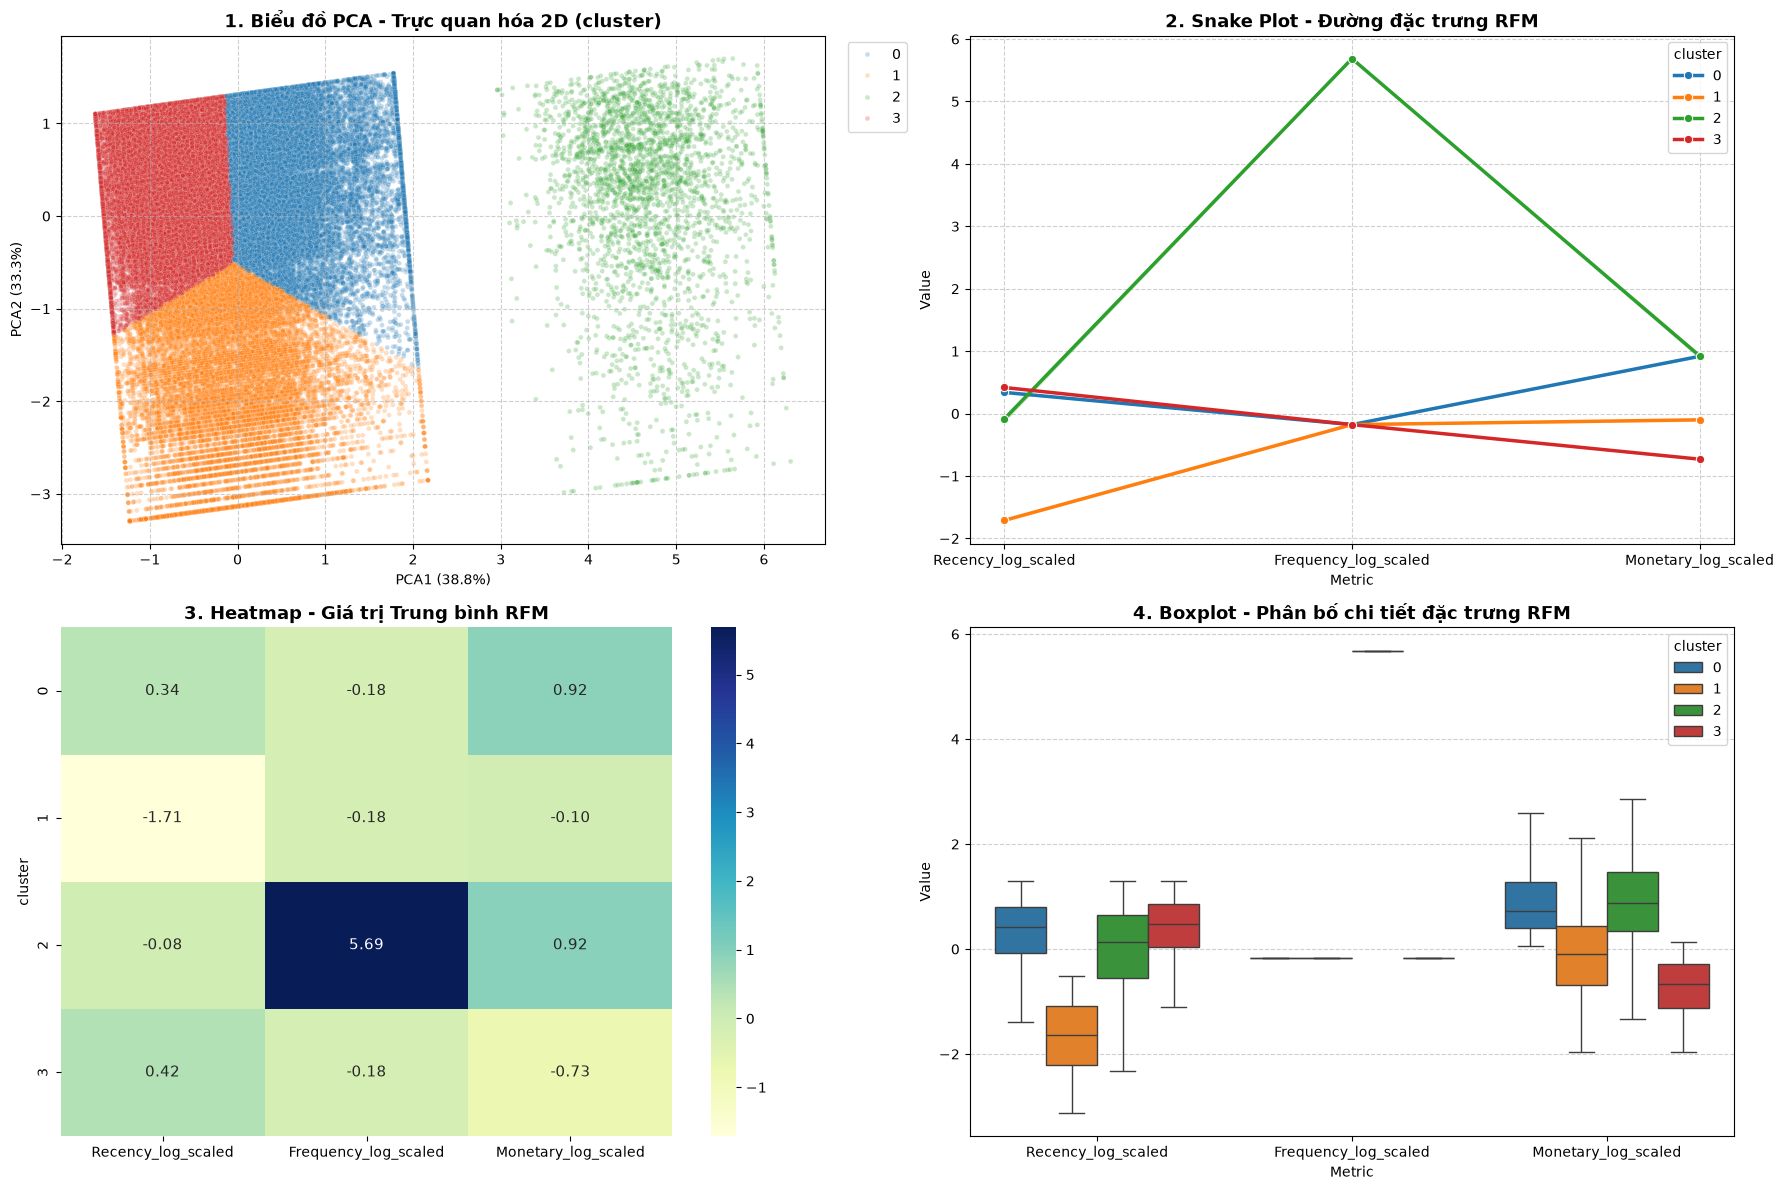

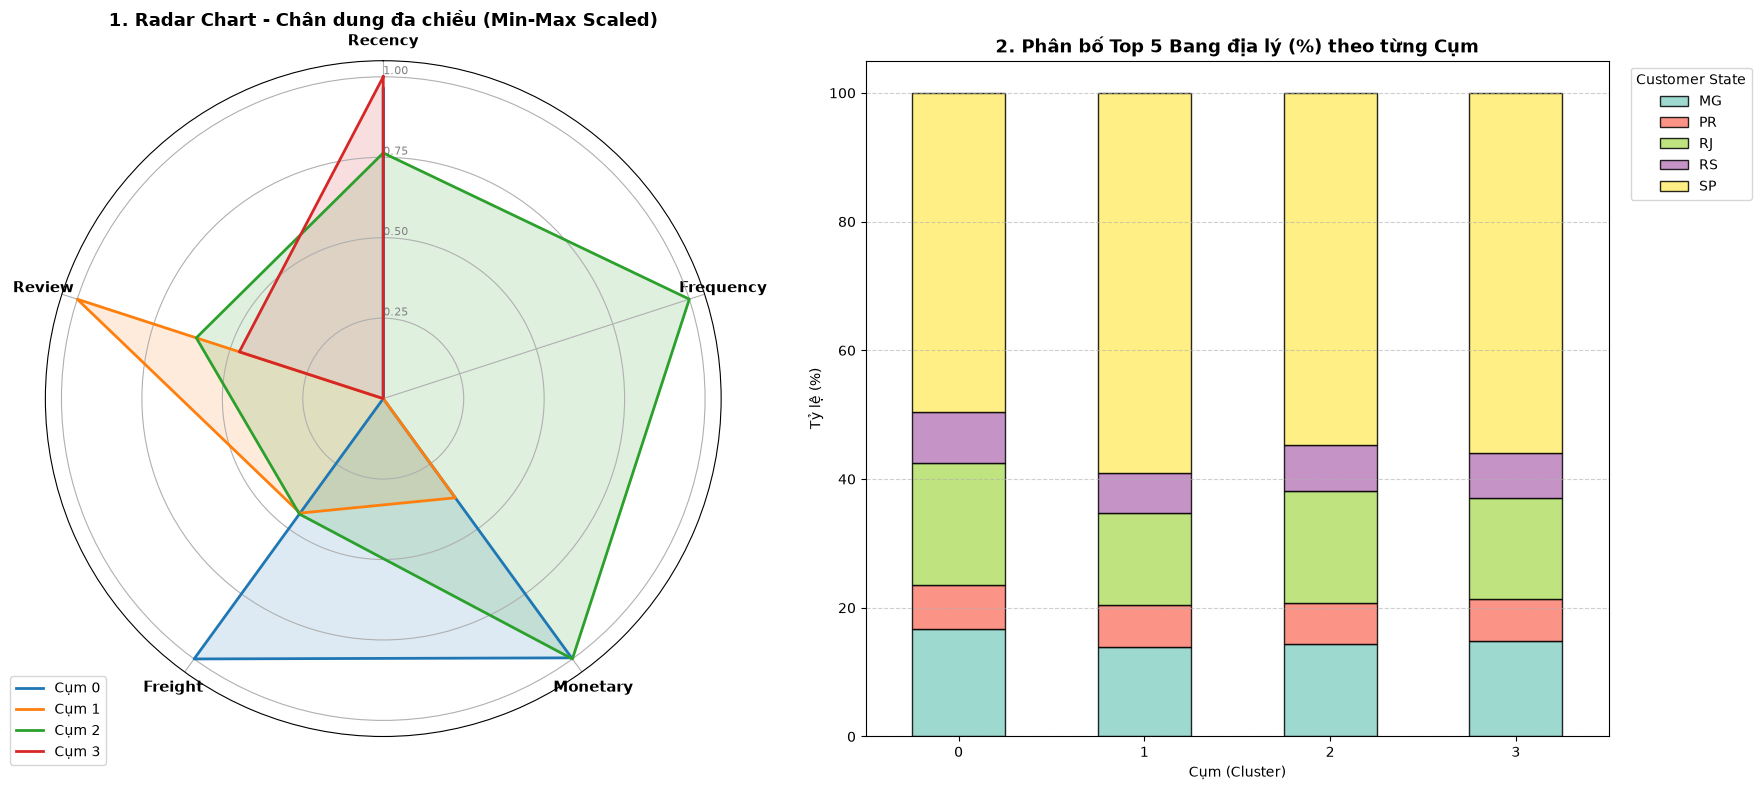

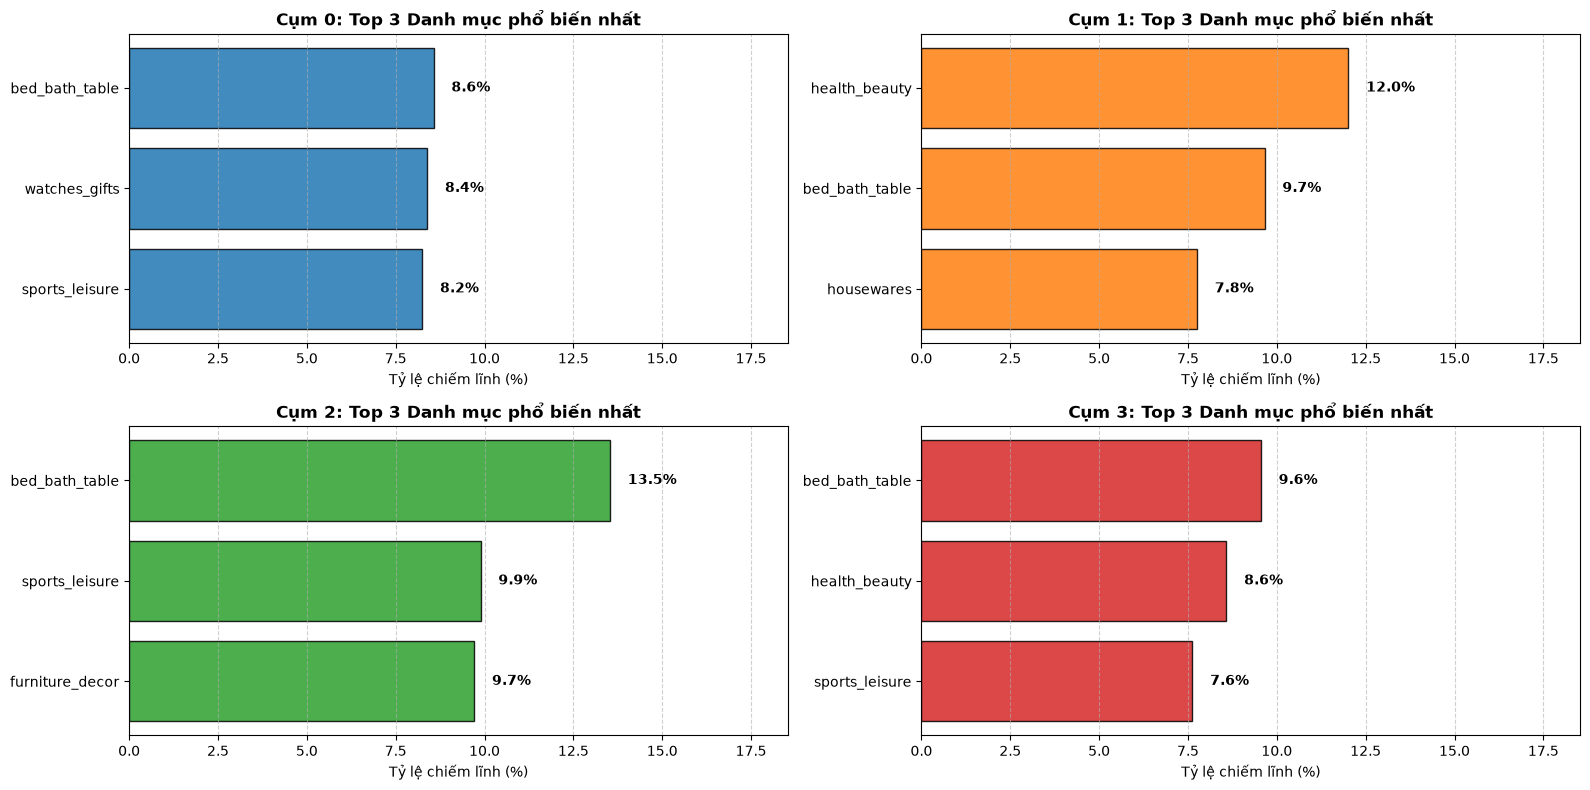

In [1]:
import sys
from pathlib import Path
import pandas as pd

# 1. Thêm thư mục gốc vào sys.path
project_root = Path.cwd().parent
if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

from src.visualization import ClusterVisualizer

# 2. Đọc dữ liệu
csv_path = project_root / 'data' / 'processed' / 'rfm_kmeans_merged_detail.csv'
df_merged = pd.read_csv(csv_path)

# 3. Chuyển tên cột 'Cluster' thành 'cluster' viết thường để khớp với code trong src
df_merged = df_merged.rename(columns={'Cluster': 'cluster'})

# 4. Khởi tạo visualizer với cluster_col='cluster'
viz = ClusterVisualizer(df_merged, cluster_col='cluster')

# 5. Chạy các biểu đồ
viz.plot_rfm_overview()

viz.plot_business_insights(
    freight_col='freight_value',
    review_col='review_score',
    state_col='customer_state',
)

viz.plot_top_categories(category_col='category', top_n=3)